In [1]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
!unzip "/content/drive/MyDrive/lise makale data/200X_CNN_Binary_data.zip"

In [ ]:
dataname= "200X_Data"
adenosis = glob("/content/"+dataname+"_CNN_DATA/train/adenosis/*.png")
print("train adenosis",len(adenosis))

fibroadenoma = glob("/content/"+dataname+"_CNN_DATA/train/fibroadenoma/*.png")
print("train fibroadenoma",len(fibroadenoma))


phyllodes_tumor = glob("/content/"+dataname+"_CNN_DATA/train/phyllodes_tumor/*.png")
print("train phyllodes_tumor",len(phyllodes_tumor))


tubular_adenoma = glob("/content/"+dataname+"_CNN_DATA/train/tubular_adenoma/*.png")
print("train tubular_adenoma",len(tubular_adenoma))


ductal_carcinoma = glob("/content/"+dataname+"_CNN_DATA/train/ductal_carcinoma/*.png")
print("train ductal_carcinoma",len(ductal_carcinoma))


lobular_carcinoma = glob("/content/"+dataname+"_CNN_DATA/train/lobular_carcinoma/*.png")
print("train lobular_carcinoma",len(lobular_carcinoma))


mucinous_carcinoma = glob("/content/"+dataname+"_CNN_DATA/train/mucinous_carcinoma/*.png")
print("train mucinous_carcinoma",len(mucinous_carcinoma))


papillary_carcinoma = glob("/content/"+dataname+"_CNN_DATA/train/papillary_carcinoma/*.png")
print("train papillary_carcinoma",len(papillary_carcinoma))


print("-----------")

adenosis = glob("/content/"+dataname+"_CNN_DATA/test/adenosis/*.png")
print("test adenosis",len(adenosis))

fibroadenoma = glob("/content/"+dataname+"_CNN_DATA/test/fibroadenoma/*.png")
print("test fibroadenoma",len(fibroadenoma))


phyllodes_tumor = glob("/content/"+dataname+"_CNN_DATA/test/phyllodes_tumor/*.png")
print("test phyllodes_tumor",len(phyllodes_tumor))


tubular_adenoma = glob("/content/"+dataname+"_CNN_DATA/test/tubular_adenoma/*.png")
print("test tubular_adenoma",len(tubular_adenoma))


ductal_carcinoma = glob("/content/"+dataname+"_CNN_DATA/test/ductal_carcinoma/*.png")
print("test ductal_carcinoma",len(ductal_carcinoma))


lobular_carcinoma = glob("/content/"+dataname+"_CNN_DATA/test/lobular_carcinoma/*.png")
print("test lobular_carcinoma",len(lobular_carcinoma))


mucinous_carcinoma = glob("/content/"+dataname+"_CNN_DATA/test/mucinous_carcinoma/*.png")
print("test mucinous_carcinoma",len(mucinous_carcinoma))


papillary_carcinoma = glob("/content/"+dataname+"_CNN_DATA/test/papillary_carcinoma/*.png")
print("test papillary_carcinoma",len(papillary_carcinoma))




train adenosis 77
train fibroadenoma 184
train phyllodes_tumor 75
train tubular_adenoma 98
train ductal_carcinoma 140
train lobular_carcinoma 114
train mucinous_carcinoma 137
train papillary_carcinoma 94
-----------
test adenosis 34
test fibroadenoma 80
test phyllodes_tumor 33
test tubular_adenoma 42
test ductal_carcinoma 60
test lobular_carcinoma 49
test mucinous_carcinoma 59
test papillary_carcinoma 41


In [3]:
from glob import  glob
import os
import shutil
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import os
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import warnings
import matplotlib.pyplot as plt
from sklearn import model_selection
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

import cv2
import random


In [4]:
from keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import ReduceLROnPlateau
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers import RMSprop
from keras import regularizers
from keras.layers.core import Dropout
from keras.applications.vgg16 import VGG16
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.losses import categorical_crossentropy
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.applications import Xception
from sklearn.metrics import precision_score, f1_score, recall_score, accuracy_score, roc_auc_score
from tensorflow.keras.layers import Dense, Activation, Dropout, Flatten, GlobalAveragePooling2D, BatchNormalization, ZeroPadding2D
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau


In [5]:
train = '/content/200X_CNN_binary_Data'
test =  '/content/200X_CNN_binary_Data'

classes = ["benign","malignant"]

In [6]:
train_data = ImageDataGenerator(rescale=1./255,
                                   zoom_range=0.3,validation_split=0.15,
                                   horizontal_flip=True)
test_data = ImageDataGenerator(rescale=1./255)



traindata = train_data.flow_from_directory(train,
                                                batch_size=8,subset = "training",
                                                target_size=(224,224),
                                                shuffle=True,
                                                color_mode='rgb',
                                                class_mode='categorical')

validationdata = train_data.flow_from_directory(train,
                                                batch_size=8,
                                                target_size=(224,224),subset = "validation",
                                                shuffle=True,
                                                color_mode='rgb',
                                                class_mode='categorical')

testdata = test_data.flow_from_directory(test,
                                                batch_size=8,
                                                target_size=(224,224),
                                                shuffle=False,
                                                color_mode='rgb',
                                                class_mode='categorical')
train_size = len(traindata.filenames)
validation_size = len(validationdata.filenames)


Found 1121 images belonging to 2 classes.
Found 196 images belonging to 2 classes.
Found 1317 images belonging to 2 classes.


In [ ]:
batch_size = 16
Xceptionmodel = Xception(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

x = Dropout(.1)(Xceptionmodel.output)
x = GlobalAveragePooling2D()(x)
#x = GlobalAveragePooling2D()(res.output)
#x = Flatten()(x)
#x = Dropout(.2)(x)
#x = Dense(units=2056, activation='relu')(x)
#x = Dense(units=1028, activation='relu')(x)
output = Dense(units=2, activation='sigmoid')(x)
#output = Dense(units=5, activation='sigmoid')(x)
Xceptionmodel = Model(inputs=Xceptionmodel.input, outputs=output)


for layer in Xceptionmodel.layers[:]:
    layer.trainable = False

for layer in Xceptionmodel.layers[-20:]:
    layer.trainable = True

for i, layer in enumerate(Xceptionmodel.layers): print(i, layer.name, layer.trainable)

Xceptionmodel.compile(optimizer=Adam(learning_rate=0.01), loss='binary_crossentropy', metrics=['binary_accuracy'])

es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=22)

Xceptionmodel.summary()


In [26]:
checkpoint_filepath = "./check_pointaccyeni"
model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=False,
    monitor='val_binary_accuracy',
    mode='max',
    save_best_only=True)

checkpoint_filepath = "./check_pointlosyeni"
model_checkpoint_callback_loss = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=False,
    monitor='val_loss',
    mode='min',
    save_best_only=True)

reduce_lr = ReduceLROnPlateau(monitor='val_loss',
                              factor=0.2,
                              patience=5,
                              verbose=2,
                              min_delta=0.0001)

In [27]:
history = Xceptionmodel.fit(traindata,
                    steps_per_epoch=(train_size//batch_size),
                    validation_data=validationdata,
                    validation_steps=(validation_size//batch_size),
                    epochs= 100 ,
                    callbacks=[model_checkpoint_callback, model_checkpoint_callback_loss, reduce_lr, es],
                    verbose=1
                    )


Epoch 1/100
70/70 [==============================] - ETA: 0s - loss: 0.7076 - binary_accuracy: 0.6857

70/70 [==============================] - 117s 2s/step - loss: 0.7076 - binary_accuracy: 0.6857 - val_loss: 8.1275 - val_binary_accuracy: 0.7083 - lr: 0.0100
Epoch 2/100
70/70 [==============================] - ETA: 0s - loss: 0.6522 - binary_accuracy: 0.6714

70/70 [==============================] - 36s 511ms/step - loss: 0.6522 - binary_accuracy: 0.6714 - val_loss: 0.7696 - val_binary_accuracy: 0.6146 - lr: 0.0100
Epoch 3/100
70/70 [==============================] - 21s 298ms/step - loss: 0.6320 - binary_accuracy: 0.6750 - val_loss: 1.2467 - val_binary_accuracy: 0.6875 - lr: 0.0100
Epoch 4/100
70/70 [==============================] - 20s 288ms/step - loss: 0.6596 - binary_accuracy: 0.6609 - val_loss: 1.8559 - val_binary_accuracy: 0.6198 - lr: 0.0100
Epoch 5/100
70/70 [==============================] - 17s 245ms/step - loss: 0.6222 - binary_accuracy: 0.6998 - val_loss: 1.9465 - val_binary_accuracy: 0.6250 - lr: 0.0100
Epoch 6/100
70/70 [==============================] - ETA: 0s - loss: 0.6263 - binary_accuracy: 0.6920

70/70 [==============================] - 35s 497ms/step - loss: 0.6263 - binary_accuracy: 0.6920 - val_loss: 0.6402 - val_binary_accuracy: 0.6771 - lr: 0.0100
Epoch 7/100
70/70 [==============================] - 17s 242ms/step - loss: 0.6201 - binary_accuracy: 0.6944 - val_loss: 0.6617 - val_binary_accuracy: 0.6615 - lr: 0.0100
Epoch 8/100
70/70 [==============================] - 17s 242ms/step - loss: 0.6240 - binary_accuracy: 0.6946 - val_loss: 0.7656 - val_binary_accuracy: 0.5781 - lr: 0.0100
Epoch 9/100
70/70 [==============================] - ETA: 0s - loss: 0.6119 - binary_accuracy: 0.7063

70/70 [==============================] - 37s 534ms/step - loss: 0.6119 - binary_accuracy: 0.7063 - val_loss: 0.6282 - val_binary_accuracy: 0.7083 - lr: 0.0100
Epoch 10/100
70/70 [==============================] - 17s 242ms/step - loss: 0.6056 - binary_accuracy: 0.7215 - val_loss: 0.6305 - val_binary_accuracy: 0.6771 - lr: 0.0100
Epoch 11/100
70/70 [==============================] - ETA: 0s - loss: 0.6225 - binary_accuracy: 0.6998

70/70 [==============================] - 35s 502ms/step - loss: 0.6225 - binary_accuracy: 0.6998 - val_loss: 0.6049 - val_binary_accuracy: 0.7083 - lr: 0.0100
Epoch 12/100
70/70 [==============================] - 17s 244ms/step - loss: 0.6034 - binary_accuracy: 0.7161 - val_loss: 0.7843 - val_binary_accuracy: 0.6146 - lr: 0.0100
Epoch 13/100
70/70 [==============================] - ETA: 0s - loss: 0.6186 - binary_accuracy: 0.6899

70/70 [==============================] - 33s 481ms/step - loss: 0.6186 - binary_accuracy: 0.6899 - val_loss: 0.5910 - val_binary_accuracy: 0.7083 - lr: 0.0100
Epoch 14/100
70/70 [==============================] - ETA: 0s - loss: 0.6357 - binary_accuracy: 0.6854

70/70 [==============================] - 35s 498ms/step - loss: 0.6357 - binary_accuracy: 0.6854 - val_loss: 0.9999 - val_binary_accuracy: 0.7292 - lr: 0.0100
Epoch 15/100
70/70 [==============================] - 17s 244ms/step - loss: 0.6207 - binary_accuracy: 0.6964 - val_loss: 0.7028 - val_binary_accuracy: 0.6458 - lr: 0.0100
Epoch 16/100
70/70 [==============================] - 17s 250ms/step - loss: 0.6107 - binary_accuracy: 0.7071 - val_loss: 0.6450 - val_binary_accuracy: 0.6458 - lr: 0.0100
Epoch 17/100
70/70 [==============================] - ETA: 0s - loss: 0.6287 - binary_accuracy: 0.6835

70/70 [==============================] - 50s 728ms/step - loss: 0.6287 - binary_accuracy: 0.6835 - val_loss: 0.5711 - val_binary_accuracy: 0.7604 - lr: 0.0100
Epoch 18/100
70/70 [==============================] - 17s 244ms/step - loss: 0.6158 - binary_accuracy: 0.6962 - val_loss: 0.6577 - val_binary_accuracy: 0.6667 - lr: 0.0100
Epoch 19/100
70/70 [==============================] - 20s 280ms/step - loss: 0.5954 - binary_accuracy: 0.7161 - val_loss: 0.6456 - val_binary_accuracy: 0.6719 - lr: 0.0100
Epoch 20/100
70/70 [==============================] - 17s 246ms/step - loss: 0.6124 - binary_accuracy: 0.7000 - val_loss: 0.6474 - val_binary_accuracy: 0.6562 - lr: 0.0100
Epoch 21/100
70/70 [==============================] - 17s 244ms/step - loss: 0.6212 - binary_accuracy: 0.6926 - val_loss: 0.5973 - val_binary_accuracy: 0.7083 - lr: 0.0100
Epoch 22/100
70/70 [==============================] - ETA: 0s - loss: 0.6203 - binary_accuracy: 0.6926
Epoch 22: ReduceLROnPlateau reducing learning rate

In [ ]:
import json,codecs
with open("history.json","w") as f:
    json.dump(history.history,f)
with codecs.open("history.json","r",encoding="utf-8") as f:
    n = json.loads(f.read())

In [28]:
score_val_model = Xceptionmodel.evaluate(validationdata, steps = len(validationdata), verbose = 0)
print('val loss:', score_val_model[0])
print('val accuracy:', score_val_model[1])


val loss: 0.6345098614692688
val accuracy: 0.6734693646430969


In [29]:
score_test_model = Xceptionmodel.evaluate(testdata, steps = len(testdata), verbose = 0)
print('Test loss:', score_test_model[0])
print('Test accuracy:', score_test_model[1])


Test loss: 0.602073609828949
Test accuracy: 0.6958997845649719


In [30]:
import keras
# Calling `save('my_model')` creates a SavedModel folder `my_model`.
Xceptionmodel.save("/content/drive/MyDrive/lise makale/Xceptionmodel/binary_train 3/Xceptionmodel.h5")


In [32]:
Xceptionmodel = keras.models.load_model('/content/drive/MyDrive/lise makale/Xceptionmodel/binary_train 3/Xceptionmodel.h5')

In [33]:
preds_Xceptionmodel = Xceptionmodel.predict(testdata,steps=len(testdata))

165/165 [==============================] - 26s 154ms/step


In [ ]:
plt.plot(n["loss"],label = "training loss")
plt.plot(n["val_loss"],label = "validation loss")
plt.savefig('LOSS.png')
plt.legend()
plt.show()


plt.plot(n["accuracy"],label = "training acc")
plt.plot(n["val_accuracy"],label = "validation acc")
plt.savefig('accuracy.png')
plt.legend()
plt.show()



In [ ]:

shutil.copy("/content/LOSS.png","/content/drive/MyDrive/lise makale/Xceptionmodel/binary_train 3")
shutil.copy("/content/accuracy.png","/content/drive/MyDrive/lise makale/Xceptionmodel/binary_train 3")

165/165 [==============================] - 21s 124ms/step


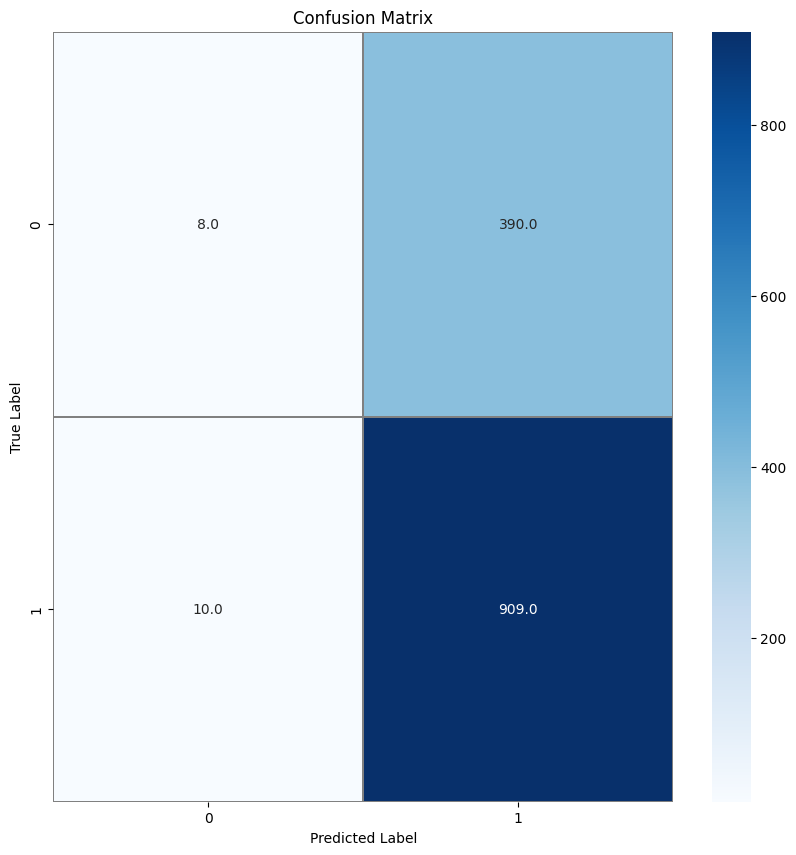

In [35]:
from sklearn.metrics import confusion_matrix
import seaborn as sns


Y_pred = Xceptionmodel.predict(testdata)
y_pred = np.argmax(Y_pred, axis=1)

confusion_mtx = confusion_matrix(testdata.classes, y_pred)
f,ax = plt.subplots(figsize=(10, 10))

sns.heatmap(confusion_mtx, annot=True, linewidths=0.01,cmap="Blues",linecolor="gray", fmt= '.1f',ax=ax)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.savefig('Confusion Matrix.png')

plt.show()

In [36]:
shutil.copy("/content/Confusion Matrix.png","/content/drive/MyDrive/lise makale/Xceptionmodel/binary_train 3")

'/content/drive/MyDrive/lise makale/Xceptionmodel/binary_train 3/Confusion Matrix.png'

In [37]:
print("Micro Precision: %f "%precision_score(testdata.classes, y_pred, average='micro'))
print("Micro Recall: %f "%recall_score(testdata.classes, y_pred, average='micro'))
print("Micro F1: %f"% f1_score(testdata.classes, y_pred, average='micro'))
#print("AUC Score: %f"%roc_auc_score(y_true, y_pred, average='micro'))
print("\n")

print("Acuracy: %f "%accuracy_score(testdata.classes, y_pred))
print("Macro Precision: %f "%precision_score(testdata.classes, y_pred, average='macro'))
print("Macro Recall: %f "%recall_score(testdata.classes, y_pred, average='macro'))
print("Macro F1: %f"% f1_score(testdata.classes, y_pred, average='macro'))
#print("AUC Score: %f"%roc_auc_score(testdata.classes, y_pred, average='macro'))
print("\n")

print("Weighted Precision: %f "%precision_score(testdata.classes, y_pred, average='weighted'))
print("Weighted Recall: %f "%recall_score(testdata.classes, y_pred, average='weighted'))
print("Weighted F1: %f"% f1_score(testdata.classes, y_pred, average='weighted'))
#print("ROC_AUC Score: %f"%roc_auc_score(testdata.classes, y_pred, average='weighted'))

Micro Precision: 0.696279 
Micro Recall: 0.696279 
Micro F1: 0.696279


Acuracy: 0.696279 
Macro Precision: 0.572107 
Macro Recall: 0.504610 
Macro F1: 0.429059


Weighted Precision: 0.622609 
Weighted Recall: 0.696279 
Weighted F1: 0.583578
